In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

In [2]:
vocab_size = 10000

(x_train, y_train), (x_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("Training Samples:", len(x_train))
print("Testing Samples:", len(x_test))

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Samples: 25000
Testing Samples: 25000


In [3]:
max_length = 200

x_train = pad_sequences(
    x_train, maxlen=max_length
)

x_test = pad_sequences(
    x_test, maxlen=max_length
)

print("Training Shape:", x_train.shape)
print("Testing Shape:", x_test.shape)

Training Shape: (25000, 200)
Testing Shape: (25000, 200)


In [4]:
model = Sequential([
    Embedding(vocab_size, 32),

    LSTM(32),

    Dense(1, activation='sigmoid')
])

In [5]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [6]:
history = model.fit(
    x_train, y_train,
    epochs=3,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 18s 54ms/step - accuracy: 0.7791 - loss: 0.4604 - val_accuracy: 0.8516 - val_loss: 0.3585
Epoch 2/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 20s 51ms/step - accuracy: 0.8954 - loss: 0.2683 - val_accuracy: 0.8766 - val_loss: 0.3196
Epoch 3/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 16s 51ms/step - accuracy: 0.9312 - loss: 0.1899 - val_accuracy: 0.8720 - val_loss: 0.3109


In [7]:
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy * 100, "%")

782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.8656 - loss: 0.3250
Test Loss: 0.3250112533569336
Test Accuracy: 86.56399846076965 %


In [8]:
predictions = model.predict(x_test[:5])

for i in range(5):

    if predictions[i][0] >= 0.5:
        sentiment = "Positive"
    else:
        sentiment = "Negative"

    print("Actual:", "Positive" if y_test[i] == 1 else "Negative")
    print("Predicted:", sentiment)
    print()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step
Actual: Negative
Predicted: Negative

Actual: Positive
Predicted: Positive

Actual: Positive
Predicted: Positive

Actual: Negative
Predicted: Positive

Actual: Positive
Predicted: Positive



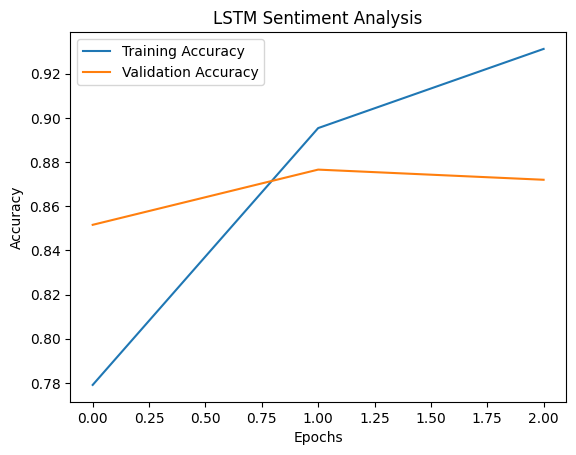

In [9]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('LSTM Sentiment Analysis')
plt.legend()
plt.show()